# Tahap 1 KDD - Data Selection

Audit dataset foto ban (terbaca / duplikat / buram) lalu pembagian train-test.

| | |
|---|---|
| **Tujuan** | Memilih data yang layak dipakai dan memisahkan data uji sejak awal. |
| **Masukan** | `data/raw/{baik, sedang, aus}` |
| **Keluaran** | `data/processed/audit.csv`, `data/processed/splits.csv`, `reports/figures/distribusi_kelas.png` |

Jalankan notebook dari folder induk proyek (atau dari `notebooks/` - sel pertama otomatis menyesuaikan).

In [1]:
%matplotlib inline

import os
import sys
from pathlib import Path

# Pastikan kernel berada di folder induk proyek agar `import config` berfungsi
HERE = Path.cwd().resolve()
ROOT = HERE.parent if HERE.name == "notebooks" else HERE
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import config as C

print("ROOT      :", ROOT)
print("Folder data:", C.RAW_DIR)
print("Kelas     :", C.CLASSES)

import hashlib

import cv2
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit, train_test_split

EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

C.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
C.FIG_DIR.mkdir(parents=True, exist_ok=True)

for k in C.CLASSES:
    n = len([p for p in (C.RAW_DIR / k).glob("*") if p.suffix.lower() in EXT])
    print(f"  {k:8s}: {n} foto")

ROOT      : D:\Perkuliahan\Machine Learning teori\Ban_Motor
Folder data: D:\Perkuliahan\Machine Learning teori\Ban_Motor\data\raw
Kelas     : ['baik', 'sedang', 'aus']


  baik    : 215 foto
  sedang  : 132 foto
  aus     : 229 foto


## 1.1 Audit tiap foto

Tiap foto dinilai:

- **tidak terbaca** - `cv2.imread` gagal;
- **duplikat** - MD5 sama dengan foto lain (buang, sisakan yang pertama);
- **buram** - *variance of Laplacian* di bawah `BLUR_THRESHOLD` (default 50.0).

Foto yang gagal salah satu pemeriksaan ditandai `valid=False` beserta alasannya.

In [2]:
def audit():
    rows = []
    for label in C.CLASSES:
        for p in sorted((C.RAW_DIR / label).glob("*")):
            if p.suffix.lower() not in EXT:
                continue
            img = cv2.imread(str(p))
            if img is None:
                rows.append(dict(path=str(p), label=label, valid=False, reason="tidak terbaca"))
                continue
            h, w = img.shape[:2]
            gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
            blur = cv2.Laplacian(gray, cv2.CV_64F).var()
            md5 = hashlib.md5(p.read_bytes()).hexdigest()
            rows.append(dict(path=str(p), label=label, width=w, height=h,
                             blur_score=round(blur, 2), md5=md5, valid=True, reason=""))
    df = pd.DataFrame(rows)
    dup = df["valid"] & df.duplicated("md5", keep="first")
    df.loc[dup, "reason"] = "duplikat"
    df.loc[dup, "valid"] = False
    buram = df["valid"] & (df["blur_score"] < C.BLUR_THRESHOLD)
    df.loc[buram, "reason"] = "buram"
    df.loc[buram, "valid"] = False
    return df


df_audit = audit()
df_audit.to_csv(C.PROCESSED_DIR / "audit.csv", index=False)

print("Ringkasan audit (jumlah per kelas x valid):")
display(df_audit.groupby(["label", "valid"]).size().unstack(fill_value=0))
print("Alasan dibuang:")
display(df_audit.loc[~df_audit["valid"], "reason"].value_counts())
display(df_audit.head())

Ringkasan audit (jumlah per kelas x valid):


valid,False,True
label,,
aus,17,212
baik,26,189
sedang,4,128


Alasan dibuang:


reason
buram    47
Name: count, dtype: int64

,path,label,width,height,blur_score,md5,valid,reason
0,D:\Perkuliahan\Machine Learning teori\Ban_Moto...,baik,290,386,201.48,0eaefe8d1024285b431670af7c59f4f3,True,
1,D:\Perkuliahan\Machine Learning teori\Ban_Moto...,baik,1000,1334,237.23,9565c4cc89a88fac23e097b1f6e11cab,True,
2,D:\Perkuliahan\Machine Learning teori\Ban_Moto...,baik,1000,1334,505.61,83d34a86a3f3744458136da732a25020,True,
3,D:\Perkuliahan\Machine Learning teori\Ban_Moto...,baik,320,426,190.98,781f498d2785dc89c37fdb8b44b39b32,True,
4,D:\Perkuliahan\Machine Learning teori\Ban_Moto...,baik,1158,1542,232.78,2c3bdbad7c1359241ac7985ab1b52bab,True,


### Pemeriksaan ambang buram

Bila banyak foto bagus ikut terbuang, turunkan `BLUR_THRESHOLD` di `config.py` lalu jalankan ulang seluruh notebook. Histogram di bawah membantu memilih ambang.

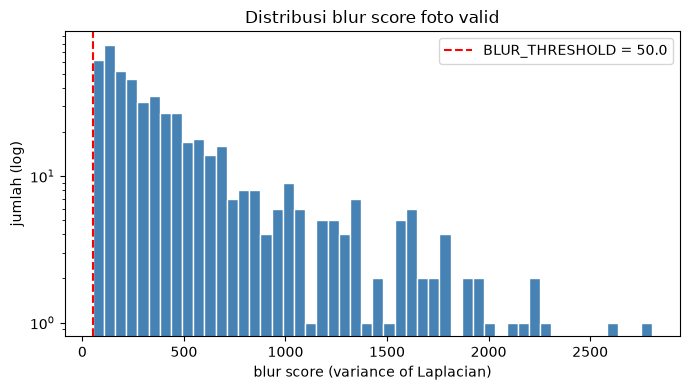

In [3]:
plt.figure(figsize=(7, 4))
v = df_audit[df_audit["valid"]]
plt.hist(v["blur_score"], bins=50, color="steelblue", edgecolor="white")
plt.axvline(C.BLUR_THRESHOLD, color="red", linestyle="--",
            label=f"BLUR_THRESHOLD = {C.BLUR_THRESHOLD}")
plt.yscale("log")
plt.xlabel("blur score (variance of Laplacian)")
plt.ylabel("jumlah (log)")
plt.title("Distribusi blur score foto valid")
plt.legend()
plt.tight_layout()
plt.show()

## 1.2 Pembagian train / test

- Data valid dibagi **80% train / 20% test** secara bertingkat (*stratified*) per kelas.
- Set test **dikunci** dan tidak boleh dipakai untuk tuning (Tahap 4).
- Semua keacakan memakai `RANDOM_STATE = 42`.
- `GROUP_BY_TIRE_ID = False`: nama file (`ban_bagus_18.jpg`) tidak memuat ID ban, dan nama file sudah unik antar kelas.

In [4]:
def split(df):
    v = df[df["valid"]].copy()
    if C.GROUP_BY_TIRE_ID:
        v["group"] = v["path"].map(lambda s: Path(s).name.split("_")[0])
        gss = GroupShuffleSplit(1, test_size=C.TEST_SIZE, random_state=C.RANDOM_STATE)
        _, te = next(gss.split(v, v["label"], v["group"]))
        v["split"] = "train"
        v.iloc[te, v.columns.get_loc("split")] = "test"
    else:
        _, te = train_test_split(v.index, test_size=C.TEST_SIZE,
                                 stratify=v["label"], random_state=C.RANDOM_STATE)
        v["split"] = "train"
        v.loc[te, "split"] = "test"
    return v

In [5]:
sp = split(df_audit)
sp[["path", "label", "split"]].to_csv(C.PROCESSED_DIR / "splits.csv", index=False)

display(sp.groupby(["split", "label"]).size().unstack(fill_value=0).loc[:, C.CLASSES])
print("valid:", len(sp),
      "| train:", int((sp["split"] == "train").sum()),
      "| test:", int((sp["split"] == "test").sum()))

label,baik,sedang,aus
split,,,
test,38,26,42
train,151,102,170


valid: 529 | train: 423 | test: 106


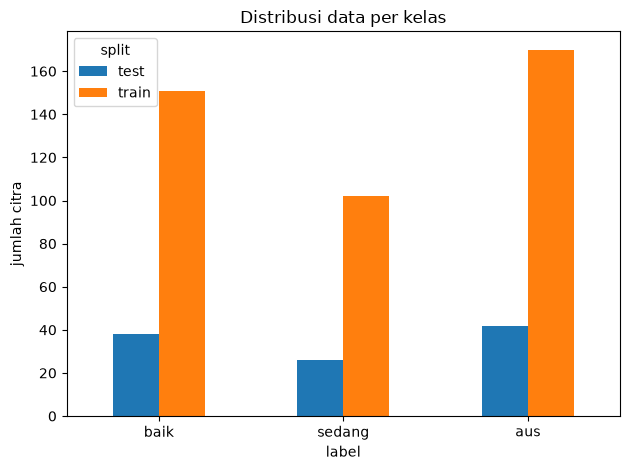

Tersimpan -> D:\Perkuliahan\Machine Learning teori\Ban_Motor\reports\figures\distribusi_kelas.png


In [6]:
ax = sp.groupby(["label", "split"]).size().unstack().loc[C.CLASSES].plot(kind="bar")
ax.set_title("Distribusi data per kelas")
ax.set_ylabel("jumlah citra")
ax.set_xticklabels(C.CLASSES, rotation=0)
plt.tight_layout()
plt.savefig(C.FIG_DIR / "distribusi_kelas.png", dpi=150)
plt.show()
print("Tersimpan ->", C.FIG_DIR / "distribusi_kelas.png")

## Periksa sebelum lanjut (Tahap 2)

- [ ] Foto valid yang terbuang tidak berlebihan (cek `audit.csv`; turunkan `BLUR_THRESHOLD` bila perlu).
- [ ] Distribusi kelas relatif seimbang pada train dan test.
- [ ] Tidak ada duplikat MD5 yang tersisa.
- [ ] Set test tidak akan dipakai untuk tuning.